# Thornquist Outfitters – Sales & Data Health Dashboard
Owner: Sukrutha · Data: `thornquist_curated` and `thornquist_quality` (Athena, workgroup `analyst-wg`)

QuickSight was not used: it may not be available in Learner Lab and costs a monthly subscription.
This notebook queries Athena directly, so every chart is built from the governed curated layer.

**How to run**
1. In Learner Lab (Ruchi's account): *AWS Details → AWS CLI → Show*, copy the block into `~/.aws/credentials` (expires with the lab session).
2. `pip install awswrangler matplotlib pandas`
3. Run all cells. If Athena access isn't available, set `MODE = "csv"` and put the query results (Athena → *Download results CSV*) in `results/` with the file names used below.

**Saved outputs:** the charts below were rendered from the curated layer's Parquet files (`MODE = "local"` on a copy of `curated/`); set `MODE = "athena"` to run the same queries live.

In [1]:
MODE = "athena"          # "athena" (live), "csv" (downloaded results) or "local" (parquet copy, for testing)
WORKGROUP = "analyst-wg"
LOCAL_LAKE = "../lake"    # only used when MODE == "local"

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Fixed colours: the same entity always has the same colour (validated colour-blind safe)
STORE, ONLINE, NEUTRAL = "#2a78d6", "#eb6834", "#52514e"
CHANNEL_COLOURS = {"in-store": STORE, "online": ONLINE}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe7",
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
money = mtick.StrMethodFormatter("${x:,.0f}")


def query(name, sql):
    """Run a query and return a DataFrame. `name` is the CSV file name in csv mode."""
    if MODE == "athena":
        import awswrangler as wr
        return wr.athena.read_sql_query(sql, database="thornquist_curated", workgroup=WORKGROUP,
                                        ctas_approach=False)
    if MODE == "csv":
        return pd.read_csv(f"results/{name}.csv")
    import duckdb                               # local testing against a parquet copy of the lake
    con = duckdb.connect()
    for schema, table, path in [
        ("thornquist_curated", "sales_fact", "curated/sales_fact"),
        ("thornquist_quality", "dq_metrics", "quality/dq_metrics"),
        ("thornquist_quality", "quarantined_sales", "quarantine/quarantined_sales")]:
        con.execute(f"CREATE SCHEMA IF NOT EXISTS {schema}")
        con.execute(f"CREATE VIEW {schema}.{table} AS SELECT * FROM "
                    f"read_parquet('{LOCAL_LAKE}/{path}/**/*.parquet', hive_partitioning=true)")
    return con.sql(sql).df()

## 1. Headline: online orders are more than twice the size of store purchases

,channel,orders,revenue,avg_order_value,units_per_order
0,in-store,1048,214561.78,204.73,1.19
1,online,226,106008.57,469.06,2.75


Average online order $469 vs in-store $205 -> 2.3x. Online orders hold 2.8 items vs 1.2.


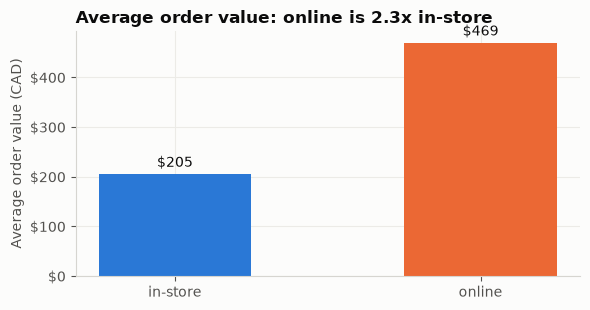

In [2]:
channel = query("q1_channel", """
SELECT channel,
       COUNT(DISTINCT transaction_id) AS orders,
       ROUND(SUM(line_amount), 2) AS revenue,
       ROUND(SUM(line_amount) / COUNT(DISTINCT transaction_id), 2) AS avg_order_value,
       ROUND(CAST(SUM(quantity) AS DOUBLE) / COUNT(DISTINCT transaction_id), 2) AS units_per_order
FROM thornquist_curated.sales_fact GROUP BY channel ORDER BY channel""")
display(channel)

store = channel.set_index("channel").loc["in-store"]
online = channel.set_index("channel").loc["online"]
ratio = online.avg_order_value / store.avg_order_value
print(f"Average online order ${online.avg_order_value:,.0f} vs in-store ${store.avg_order_value:,.0f} "
      f"-> {ratio:.1f}x. Online orders hold {online.units_per_order:.1f} items vs {store.units_per_order:.1f}.")

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(channel.channel, channel.avg_order_value, width=0.5,
              color=[CHANNEL_COLOURS[c] for c in channel.channel])
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in channel.avg_order_value], padding=3)
ax.yaxis.set_major_formatter(money)
ax.set_title(f"Average order value: online is {ratio:.1f}x in-store")
ax.set_ylabel("Average order value (CAD)")
fig.tight_layout(); fig.savefig("chart_1_order_value.png", dpi=150); plt.show()

## 2. Revenue by region and channel

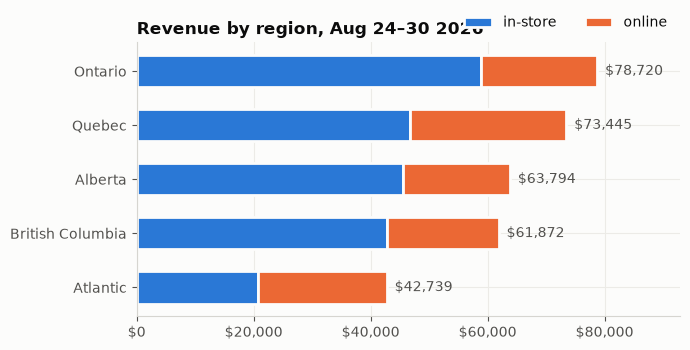

In [3]:
region = query("q_region_channel", """
SELECT region, channel, ROUND(SUM(line_amount), 2) AS revenue
FROM thornquist_curated.sales_fact GROUP BY region, channel""")
pivot = region.pivot(index="region", columns="channel", values="revenue").fillna(0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7, 3.6))
left = 0
for ch in ["in-store", "online"]:
    ax.barh(pivot.index, pivot[ch], left=left, color=CHANNEL_COLOURS[ch], label=ch,
            edgecolor="#fcfcfb", linewidth=2, height=0.6)
    left = left + pivot[ch]
for y, total in enumerate(pivot.sum(axis=1)):
    ax.text(total, y, f"  ${total:,.0f}", va="center", color="#52514e")
ax.xaxis.set_major_formatter(money)
ax.set_title("Revenue by region, Aug 24–30 2026")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_xlim(0, pivot.sum(axis=1).max() * 1.18)
fig.tight_layout(); fig.savefig("chart_2_region.png", dpi=150); plt.show()

## 2b. Revenue by product category and channel

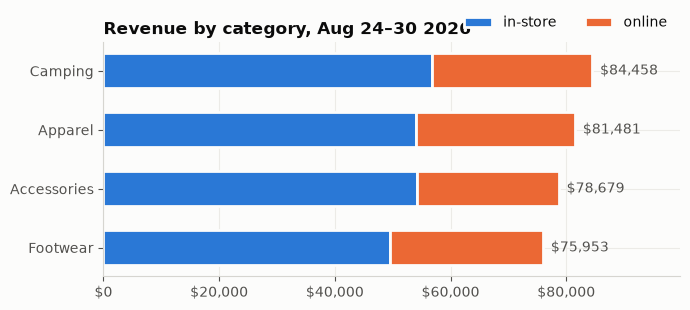

In [4]:
category = query("q_category_channel", """
SELECT category, channel, ROUND(SUM(line_amount), 2) AS revenue
FROM thornquist_curated.sales_fact GROUP BY category, channel""")
cat = category.pivot(index="category", columns="channel", values="revenue").fillna(0)
cat = cat.loc[cat.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(7, 3.2))
left = 0
for ch in ["in-store", "online"]:
    ax.barh(cat.index, cat[ch], left=left, color=CHANNEL_COLOURS[ch], label=ch,
            edgecolor="#fcfcfb", linewidth=2, height=0.6)
    left = left + cat[ch]
for y, total in enumerate(cat.sum(axis=1)):
    ax.text(total, y, f"  ${total:,.0f}", va="center", color="#52514e")
ax.xaxis.set_major_formatter(money)
ax.set_xlim(0, cat.sum(axis=1).max() * 1.18)
ax.set_title("Revenue by category, Aug 24–30 2026")
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
fig.tight_layout(); fig.savefig("chart_7_category.png", dpi=150); plt.show()

## 3. Customer segment × channel (sales blended with the customer extract)

,customer_segment,channel,orders,revenue,avg_order_value
0,Walk-in,in-store,185,35772.89,193.37
1,Standard,in-store,598,126546.90,211.62
2,Gold,in-store,82,17548.37,214.00
3,Silver,in-store,183,34693.62,189.58
4,Silver,online,52,28043.10,539.29
5,Standard,online,157,72058.86,458.97
6,Gold,online,17,5906.61,347.45


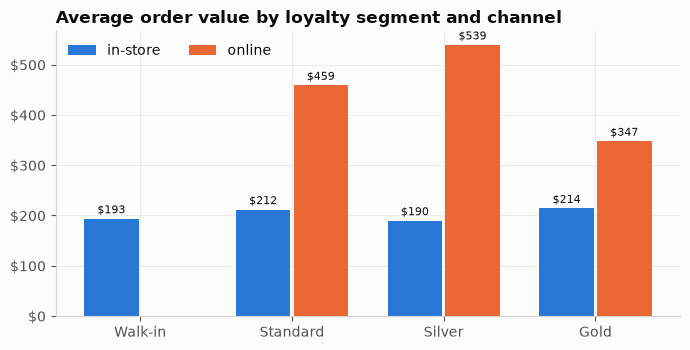

In [5]:
segment = query("q3_segment", """
SELECT customer_segment, channel,
       COUNT(DISTINCT transaction_id) AS orders,
       ROUND(SUM(line_amount), 2) AS revenue,
       ROUND(SUM(line_amount) / COUNT(DISTINCT transaction_id), 2) AS avg_order_value
FROM thornquist_curated.sales_fact GROUP BY customer_segment, channel""")
display(segment)
order = ["Walk-in", "Standard", "Silver", "Gold"]
seg = segment.pivot(index="customer_segment", columns="channel", values="avg_order_value").reindex(order)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = range(len(order)); w = 0.36
for i, ch in enumerate(["in-store", "online"]):
    vals = seg[ch]
    pos = [p + (i - 0.5) * (w + 0.02) for p in x]
    bars = ax.bar(pos, vals.fillna(0), width=w, color=CHANNEL_COLOURS[ch], label=ch)
    ax.bar_label(bars, labels=["" if pd.isna(v) else f"${v:,.0f}" for v in vals], padding=2, fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(order)
ax.yaxis.set_major_formatter(money)
ax.set_title("Average order value by loyalty segment and channel")
ax.legend(ncol=2)
fig.tight_layout(); fig.savefig("chart_3_segment.png", dpi=150); plt.show()

## 4. Daily revenue trend

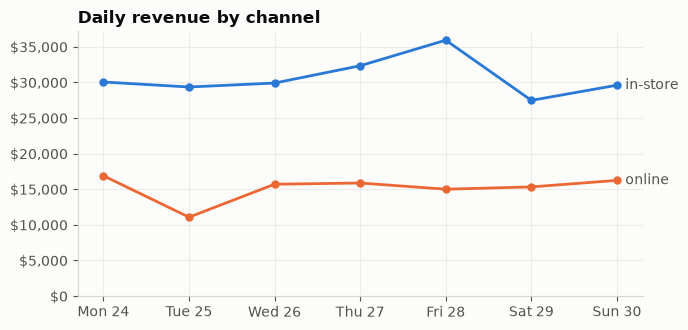

In [6]:
daily = query("q5_daily", """
SELECT sale_date, channel, ROUND(SUM(line_amount), 2) AS revenue
FROM thornquist_curated.sales_fact GROUP BY sale_date, channel ORDER BY sale_date""")
daily["sale_date"] = pd.to_datetime(daily.sale_date)

fig, ax = plt.subplots(figsize=(7, 3.4))
for ch in ["in-store", "online"]:
    d = daily[daily.channel == ch]
    ax.plot(d.sale_date, d.revenue, color=CHANNEL_COLOURS[ch], linewidth=2, marker="o", markersize=5)
    ax.annotate(ch, (d.sale_date.iloc[-1], d.revenue.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color="#52514e")
ax.yaxis.set_major_formatter(money)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d"))
ax.set_ylim(0, None)
ax.set_title("Daily revenue by channel")
fig.tight_layout(); fig.savefig("chart_4_daily.png", dpi=150); plt.show()

## 5. Data health: what the quality gate kept out, in dollars

,reason,source_system,row_count,revenue
0,orphan_customer,ecommerce,90,18361.87
1,duplicate_record,ecommerce,15,2943.95
2,duplicate_record,pos,3,720.27


16.1% of online revenue was quarantined; 16.6% of store revenue comes from anonymous walk-ins.


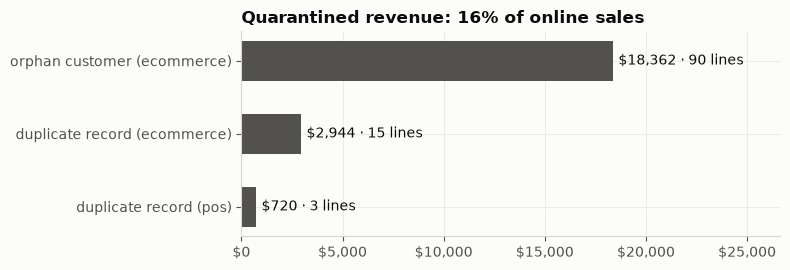

In [7]:
health = query("qa_reasons", """
SELECT metric AS reason, source_system, row_count, revenue
FROM thornquist_quality.dq_metrics
WHERE metric NOT IN ('rows_checked', 'rows_passed', 'rows_quarantined', 'info_walk_in_sales')
  AND run_date = (SELECT MAX(run_date) FROM thornquist_quality.dq_metrics)""")
totals = query("qa_totals", """
SELECT source_system, metric, row_count, revenue FROM thornquist_quality.dq_metrics
WHERE metric IN ('rows_checked', 'rows_quarantined', 'info_walk_in_sales')
  AND run_date = (SELECT MAX(run_date) FROM thornquist_quality.dq_metrics)""")
display(health)
t = totals.pivot(index="source_system", columns="metric", values="revenue")
online_risk = 100 * t.loc["ecommerce", "rows_quarantined"] / t.loc["ecommerce", "rows_checked"]
walk_in = 100 * t.loc["pos", "info_walk_in_sales"] / t.loc["pos", "rows_checked"]
print(f"{online_risk:.1f}% of online revenue was quarantined; "
      f"{walk_in:.1f}% of store revenue comes from anonymous walk-ins.")

h = health.assign(label=health.reason.str.replace("_", " ") + " (" + health.source_system + ")")
h = h.sort_values("revenue")
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(h.label, h.revenue, color=NEUTRAL, height=0.55)
ax.bar_label(bars, labels=[f"${r:,.0f} · {n} lines" for r, n in zip(h.revenue, h.row_count)], padding=4)
ax.xaxis.set_major_formatter(money)
ax.set_xlim(0, h.revenue.max() * 1.45)
ax.set_title(f"Quarantined revenue: {online_risk:.0f}% of online sales")
fig.tight_layout(); fig.savefig("chart_5_data_health.png", dpi=150); plt.show()

## 6. Walk-in blind spot by region (store sales with no customer attached)

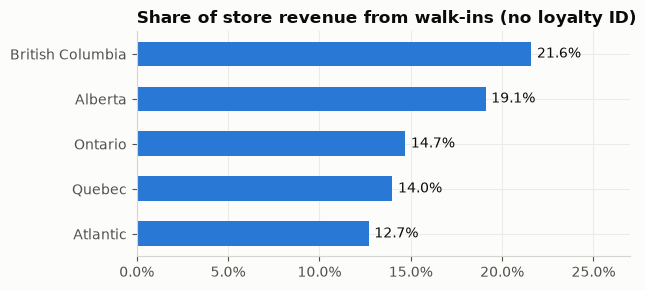

In [8]:
walk = query("q6_walk_in", """
SELECT region,
       ROUND(100 * SUM(CASE WHEN is_walk_in THEN line_amount ELSE 0 END) / SUM(line_amount), 1) AS walk_in_pct
FROM thornquist_curated.sales_fact WHERE channel = 'in-store'
GROUP BY region ORDER BY walk_in_pct""")
fig, ax = plt.subplots(figsize=(6.5, 3))
bars = ax.barh(walk.region, walk.walk_in_pct, color=STORE, height=0.55)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in walk.walk_in_pct], padding=4)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlim(0, walk.walk_in_pct.max() * 1.25)
ax.set_title("Share of store revenue from walk-ins (no loyalty ID)")
fig.tight_layout(); fig.savefig("chart_6_walk_in.png", dpi=150); plt.show()